# Epipolar geometry
A pinhole camera projects a 3D scene down to a 2D plane and thus loses the depth dimension. The solution to this problem is to use two cameras - i.e. stereo vision. If two cameras observe the same scene from offset positions, a point in the imageplane from one of the cameras will lie on a line in the imageplane of the other camera. In this exercise you will be drawing epipolar lines on a set of images to visualize where the two cameras are located in relation to each other in image coordinates.

As always, start by importing necessary libraries.

In [1]:
import cv2
import numpy as np
from matplotlib import pyplot as plt

## Exercise 2.1
Use [SIFT](https://docs.opencv.org/4.7.0/d7/d60/classcv_1_1SIFT.html) to detect and compute features in both the left and right images and optionally visualize the keypoints.

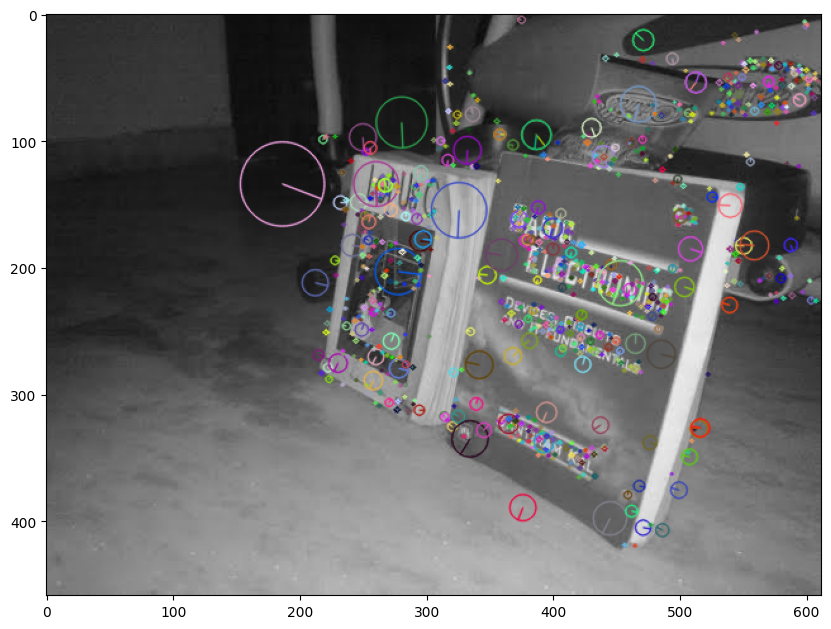

In [2]:
# Why cv2.imread(path, 0): the second argument (0) tells OpenCV to load the
# image directly as grayscale, which is what SIFT needs. We need distinctive,
# reliably re-identifiable points in both images before we can figure out the
# geometric relationship between the two camera views. SIFT's descriptors let
# us later match the same real-world point across the left/right images even
# though it appears at a slightly different position/scale in each.
# sift.detectAndCompute() returns both the keypoint locations (kp1, kp2) and
# their descriptor vectors (des1, des2) for each image in one call.
# cv2.drawKeypoints() then visualizes the detected keypoints (with
# DRAW_RICH_KEYPOINTS also showing each keypoint's scale/orientation.
img1 = cv2.imread("img_left.jpg", 0)
img2 = cv2.imread("img_right.jpg", 0)

sift = cv2.SIFT_create()

# Find the keypoints and descriptors with SIFT.
kp1, des1 = sift.detectAndCompute(img1, None)
kp2, des2 = sift.detectAndCompute(img2, None)

kp_img = cv2.drawKeypoints(
    img2, kp2, img2, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS
)
plt.figure(figsize=(10, 10))
plt.imshow(kp_img)

## Exercise 2.2
The next step is to match the features in the two images. We can do that exactly like we did in previous exercises using [`cv2.BFMatcher`](https://docs.opencv.org/4.7.0/d3/da1/classcv_1_1BFMatcher.html). 

Fill in the missing code below by implementing `cv2.BFMatcher`. Store the matching results in a variable called `matches`.

In [3]:
# Match the SIFT descriptors between the two images using brute-force matching.
# Having features in each image individually doesn't tell us how the two views
# relate to each other. Matching finds which keypoints in image 1 correspond to
# the same real-world point as which keypoints in image 2, which is exactly the
# correspondence data needed to work out the epipolar geometry. cv2.BFMatcher()
# compares every descriptor in des1 against every descriptor in des2 and returns
# each descriptor's single closest match. Sorting by '.distance' (ascending)
# puts the strongest, most reliable matches first, since a smaller descriptor
# distance means a more confident match.
bf = cv2.BFMatcher()
matches = bf.match(des1, des2)

# Sort them in the order of their distance (i.e. best matches first).
matches = sorted(matches, key=lambda x: x.distance)

The above gives us a list of best matches in proritized order. We can use the function [`findFundamentalMat`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#gae420abc34eaa03d0c6a67359609d8429) to compute the fundamental matrix using a number of the best keypoint matches.

In [4]:
# Compute the fundamental matrix from the best keypoint matches. This 3x3 matrix
# encodes the epipolar geometry between the two camera views (i.e. given a point
# in one image, it tells you exactly which line (not just an area) that same
# real-world point must lie along in the other image).
# Why only use the first 200 matches (nb_matches): using only the strongest/most
# confident matches (rather than every match found, including many weak ones)
# tends to give a more accurate fundamental matrix estimate, since the underlying
# math is sensitive to outlier/incorrect correspondences. For each of the top
# matches, 'pts1' and 'pts2' collect the actual (x, y) pixel coordinates of the
# matched keypoint in each image (looked up via each match's queryIdx/trainIdx
# into kp1/kp2 respectively). cv2.findFundamentalMat() needs these raw coordinate
# pairs, not the SIFT keypoint/match objects themselves.
# Why cv2.FM_RANSAC: even the "best" matches can still include some outliers;
# RANSAC estimates the fundamental matrix by repeatedly fitting it to random
# small subsets of the points and keeping the version that's consistent with
# the largest number of points overall, which makes the result robust to those
# bad matches.
# Why filter by 'mask': findFundamentalMat() also returns a mask marking which
# input points RANSAC considered inliers vs. outliers . Keeping only the inlier
# points cleans up pts1/pts2 for the more accurate epipolar line visualization.
nb_matches = 200

good = []
pts1 = []
pts2 = []

for m in matches[:nb_matches]:
    good.append(m)
    pts1.append(kp1[m.queryIdx].pt)
    pts2.append(kp2[m.trainIdx].pt)

pts1 = np.int32(pts1)
pts2 = np.int32(pts2)

F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC)

# We select only inlier points.
pts1 = pts1[mask.ravel() == 1]
pts2 = pts2[mask.ravel() == 1]

In order to draw the epipolar lines, we can use the following function.

In [5]:
# cv2 has no single built-in function that draws a line across the full image
# given its (a, b, c) line equation coefficients. So this helper computes two
# endpoints for each line (where it crosses the image's left and right edges)
# and draws a regular line segment between them, alongside a colored dot marking
# the actual matched keypoint. Each epipolar line is given in the form
# a*x + b*y + c = 0 (stored as [a, b, c] in 'lines'). Rearranging to solve for
# y at a given x gives y = -(a*x + c) / b. The code computes this at x=0 (the
# image's left edge) and x=img1.shape[1] (the right edge, 'c' here reusing the
# variable name for the image's column count, not the line coefficient) to get
# two points that fully span the line across the image width.
# Why convert to BGR first: cv2.line()/cv2.circle() need a 3-channel image to
# draw colored (not just grayscale) lines/points onto, so the grayscale inputs
# are converted to a 3-channel format before drawing.  Using a different random
# color for each line/point pair makes it visually easy to tell which drawn
# point in image 1 corresponds to which line in image 2 (and vice versa) when
# many lines are drawn on the same image at once.
def drawlines(img1, img2, lines, pts1, pts2):
    """img1 - image on which we draw the epilines for the points in img2
    lines - corresponding epilines"""
    r, c = img1.shape
    img1 = cv2.cvtColor(img1, cv2.COLOR_GRAY2BGR)
    img2 = cv2.cvtColor(img2, cv2.COLOR_GRAY2BGR)
    for r, pt1, pt2 in zip(lines, pts1, pts2):
        color = tuple(np.random.randint(0, 255, 3).tolist())
        x0, y0 = map(int, [0, -r[2] / r[1]])
        x1, y1 = map(int, [c, -(r[2] + r[0] * c) / r[1]])
        img1 = cv2.line(img1, (x0, y0), (x1, y1), color, 1)
        img1 = cv2.circle(img1, tuple(pt1), 5, color, -1)
        img2 = cv2.circle(img2, tuple(pt2), 5, color, -1)
    return img1, img2

## Exercise 2.3
We can then use the function [`computeCorrespondEpilines`](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html#ga19e3401c94c44b47c229be6e51d158b7), which uses the fundamental matrix and the matching keypoints.

Previously, we selected a number of the best keypoint matches. Try to decrease or increase this number and visuallise the result. What happens with the epipolar lines? Remember you have to compute the fundamental matrix again based on the new number of keypoints.

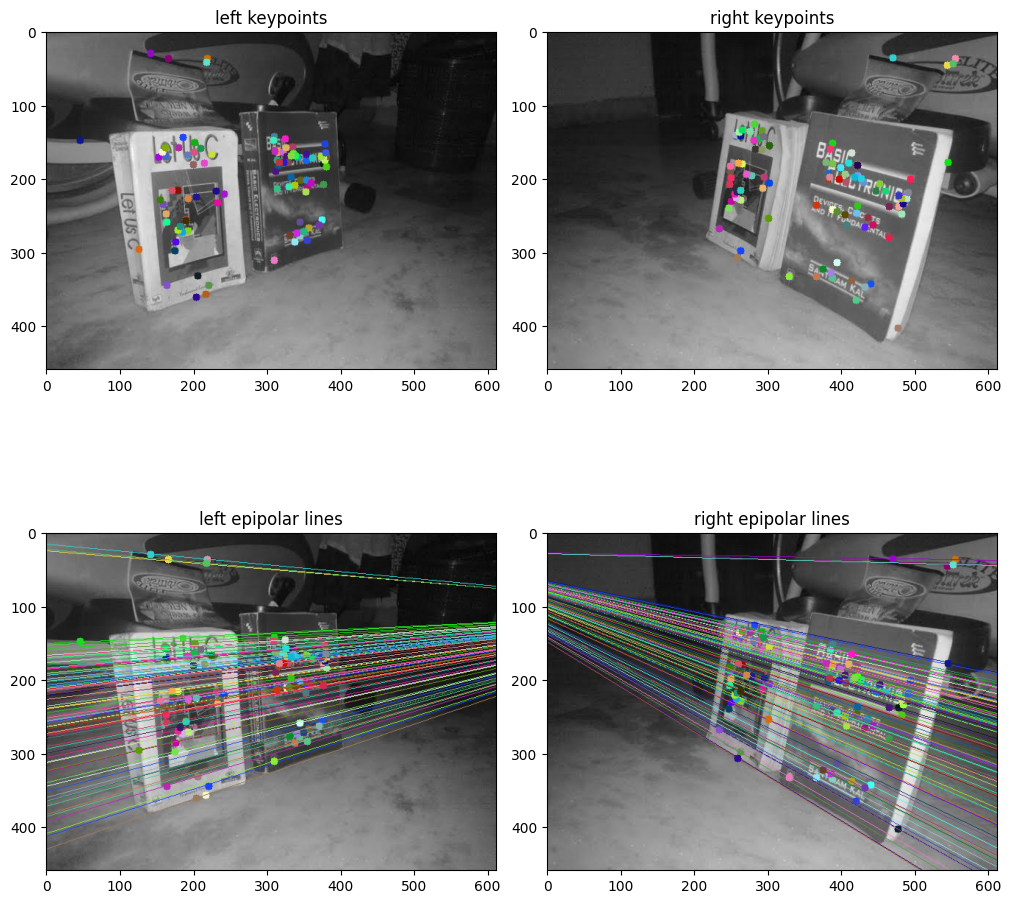

In [6]:
# Why compute lines in both directions: epipolar geometry is symmetric; just as
# points in image 2 constrain a line in image 1, points in image 1 equally
# constrain a line in image 2. Computing and drawing both directions lets us
# visually verify the geometry is consistent (that a point's epipolar line in
# one image actually passes through the matching point's location once mapped
# back). cv2.computeCorrespondEpilines computes, for each input point, the
# epipolar line it induces in the other image (whichImage identifies which image
# the input points came from; 2 means "these points are from the second/right
# image", so the returned lines belong to the first/left image, and vice versa
# for the second call). The result is reshaped from its raw (N, 1, 3) output
# shape to a simpler (N, 3) array of [a, b, c] line coefficients before being
# passed to the drawlines() helper defined above. The final 2x2 grid of subplots
# shows all four resulting images together; the plain keypoints on each image
# alongside the corresponding epipolar lines drawn on the other image, so you
# can directly compare where the keypoint actually is against where the geometry
# predicted it should lie.

# Find epilines corresponding to points in right image (second image) and
# drawing its lines on left image.
lines1 = cv2.computeCorrespondEpilines(pts2.reshape(-1, 1, 2), 2, F)
lines1 = lines1.reshape(-1, 3)
img5, img6 = drawlines(img1, img2, lines1, pts1, pts2)

# Find epilines corresponding to points in left image (first image) and
# drawing its lines on right image.
lines2 = cv2.computeCorrespondEpilines(pts1.reshape(-1, 1, 2), 1, F)
lines2 = lines2.reshape(-1, 3)
img3, img4 = drawlines(img2, img1, lines2, pts2, pts1)

fig, axs = plt.subplots(2, 2, constrained_layout=True, figsize=(10, 10))
axs[0, 0].imshow(img4)
axs[0, 0].set_title("left keypoints")
axs[0, 1].imshow(img6)
axs[0, 1].set_title("right keypoints")
axs[1, 0].imshow(img5)
axs[1, 0].set_title("left epipolar lines")
axs[1, 1].imshow(img3)
axs[1, 1].set_title("right epipolar lines")
plt.show()

## Optional exercise
The downside of using bf matcher is that it doesn't scale well when the number of keypoints increase. Instead we could opt for using `Fast Library for Approximate Nearest Neighbors (flann)` by sacrificing some accuracy. The exercise is to replace bf match in the previous exercise with a [flann based matcher](https://docs.opencv.org/4.7.0/dc/de2/classcv_1_1FlannBasedMatcher.html) and compare the results.

In [7]:
# FLANN uses efficient search structures (like KD-trees) to find approximate
# rather than exact nearest-neighbor matches. This trades a small amount of
# matching accuracy for much better scalability as the number of keypoints/descriptors
# grows, compared to BFMatcher's exhaustive pairwise comparison. FLANN_INDEX_KDTREE
# selects a KD-tree based index; trees=5 controls how many parallel KD-trees
# are built (more trees can improve accuracy at the cost of memory/speed);
# checks=50 controls how many leaf nodes are checked during each search (higher
# = more accurate but slower).
# Why knnMatch(k=2) + the ratio test: instead of returning only the single best
# match per descriptor, this asks for each descriptor's two best candidate
# matches. Lowe's ratio test then keeps a match only if the best candidate (m)
# is meaningfully closer than the second-best (n). Specifically if m.distance
# is less than 80% of n.distance, which filters out ambiguous matches where two
# candidates are nearly equally good (and thus the "best" one might just be due
# to noise rather than a genuinely distinctive match). The remaining steps are
# identical to Exercise 2.2/2.3 above.
FLANN_INDEX_KDTREE = 0
index_params = dict(algorithm=FLANN_INDEX_KDTREE, trees=5)
search_params = dict(checks=50)

flann = cv2.FlannBasedMatcher(index_params, search_params)
matches = flann.knnMatch(des1, des2, k=2)

good = []
pts1 = []
pts2 = []

# Ratio test as per Lowe's paper.
for i, (m, n) in enumerate(matches):
    if m.distance < 0.8 * n.distance:
        good.append(m)
        pts1.append(kp1[m.queryIdx].pt)
        pts2.append(kp2[m.trainIdx].pt)

pts1 = np.int32(pts1)
pts2 = np.int32(pts2)

F, mask = cv2.findFundamentalMat(pts1, pts2, cv2.FM_RANSAC)

# We select only inlier points.
pts1 = pts1[mask.ravel() == 1]
pts2 = pts2[mask.ravel() == 1]